<a href="https://colab.research.google.com/github/rito0007/Aquascope/blob/main/Kolkata_Water_Quality_XGBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Kolkata Water Quality Prediction Using XGBoost

## Project Overview

This project aims to develop a Machine Learning regression model
to estimate the Water Quality Index (WQI) of water bodies
across Kolkata.

The model uses environmental and physicochemical water quality
parameters to predict the estimated Water Quality Index.

## Dataset
- Dataset: Kolkata Water Bodies Monitoring
- Total Records: 159
- Total Features: 20
- Target Variable: estimated_wqi

## Machine Learning Algorithm
- XGBoost Regressor

## Evaluation Metrics
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)


In [ ]:
!pip install xgboost scikit-learn pandas numpy matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kolkata_water_bodies_monitoring_dataset.csv to kolkata_water_bodies_monitoring_dataset.csv


In [ ]:
df = pd.read_csv('kolkata_water_bodies_monitoring_dataset.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,record_id,water_body_name,water_body_type,district,location_zone,season,water_temp_c,ph,dissolved_oxygen_mg_l,biochemical_oxygen_demand_mg_l,chemical_oxygen_demand_mg_l,total_dissolved_solids_mg_l,turbidity_ntu,nitrate_mg_l,phosphate_mg_l,fecal_coliform_mpn_100ml,estimated_wqi,ecological_status,sensor_platform,llm_actionable_insight
0,WB-KOL-1001,Rabindra Sarobar (Dhakuria Lake),Urban Lake,Kolkata,South Kolkata,Pre-Monsoon (Summer),34.4,7.53,6.92,5.09,15.35,239,18.3,1.37,0.21,1571,95.0,Fair / Controlled Urban Water,HACH Hydrolab DS5,Parameters within safe aquatic life thresholds...
1,WB-KOL-1002,Rabindra Sarobar (Dhakuria Lake),Urban Lake,Kolkata,South Kolkata,Pre-Monsoon (Summer),31.2,7.53,5.60,4.06,16.30,306,15.2,1.84,0.21,925,88.6,Fair / Controlled Urban Water,Manual Lab Sampling (Standard APHA Methods),Parameters within safe aquatic life thresholds...
2,WB-KOL-1003,Rabindra Sarobar (Dhakuria Lake),Urban Lake,Kolkata,South Kolkata,Monsoon,28.6,7.95,5.64,4.80,17.11,229,20.9,1.09,0.18,2107,86.6,Fair / Controlled Urban Water,Manual Lab Sampling (Standard APHA Methods),Parameters within safe aquatic life thresholds...
3,WB-KOL-1004,Rabindra Sarobar (Dhakuria Lake),Urban Lake,Kolkata,South Kolkata,Monsoon,27.8,7.88,6.54,5.92,12.08,298,13.3,2.08,0.32,774,94.8,Fair / Controlled Urban Water,Manual Lab Sampling (Standard APHA Methods),Parameters within safe aquatic life thresholds...
4,WB-KOL-1005,Rabindra Sarobar (Dhakuria Lake),Urban Lake,Kolkata,South Kolkata,Post-Monsoon (Autumn),25.1,7.99,6.19,4.38,21.12,365,15.9,1.77,0.36,2130,92.2,Fair / Controlled Urban Water,Aquascan IoT In-situ Node,Parameters within safe aquatic life thresholds...


In [ ]:
print("Dataset Shape:", df.shape)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (159, 20)
Number of Rows: 159
Number of Columns: 20


In [ ]:
print(df.columns.tolist())

['record_id', 'water_body_name', 'water_body_type', 'district', 'location_zone', 'season', 'water_temp_c', 'ph', 'dissolved_oxygen_mg_l', 'biochemical_oxygen_demand_mg_l', 'chemical_oxygen_demand_mg_l', 'total_dissolved_solids_mg_l', 'turbidity_ntu', 'nitrate_mg_l', 'phosphate_mg_l', 'fecal_coliform_mpn_100ml', 'estimated_wqi', 'ecological_status', 'sensor_platform', 'llm_actionable_insight']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   record_id                       159 non-null    object 
 1   water_body_name                 159 non-null    object 
 2   water_body_type                 159 non-null    object 
 3   district                        159 non-null    object 
 4   location_zone                   159 non-null    object 
 5   season                          159 non-null    object 
 6   water_temp_c                    159 non-null    float64
 7   ph                              159 non-null    float64
 8   dissolved_oxygen_mg_l           159 non-null    float64
 9   biochemical_oxygen_demand_mg_l  159 non-null    float64
 10  chemical_oxygen_demand_mg_l     159 non-null    float64
 11  total_dissolved_solids_mg_l     159 non-null    int64  
 12  turbidity_ntu                   159 

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
record_id                         0
water_body_name                   0
water_body_type                   0
district                          0
location_zone                     0
season                            0
water_temp_c                      0
ph                                0
dissolved_oxygen_mg_l             0
biochemical_oxygen_demand_mg_l    0
chemical_oxygen_demand_mg_l       0
total_dissolved_solids_mg_l       0
turbidity_ntu                     0
nitrate_mg_l                      0
phosphate_mg_l                    0
fecal_coliform_mpn_100ml          0
estimated_wqi                     0
ecological_status                 0
sensor_platform                   0
llm_actionable_insight            0
dtype: int64


In [ ]:
df.describe()

,water_temp_c,ph,dissolved_oxygen_mg_l,biochemical_oxygen_demand_mg_l,chemical_oxygen_demand_mg_l,total_dissolved_solids_mg_l,turbidity_ntu,nitrate_mg_l,phosphate_mg_l,fecal_coliform_mpn_100ml,estimated_wqi
count,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000
mean,27.364151,7.608302,5.370314,13.548176,37.812138,486.408805,41.762264,3.602264,0.959623,13150.716981,68.645912
std,4.263226,0.382676,2.094894,16.179643,38.571400,276.116679,34.566448,3.141620,1.003516,25784.943798,27.730600
min,18.200000,6.580000,0.250000,1.540000,6.330000,182.000000,4.100000,0.450000,0.070000,80.000000,12.000000
25%,25.050000,7.395000,4.305000,3.575000,12.870000,306.000000,15.150000,1.390000,0.240000,554.500000,53.050000
50%,27.600000,7.650000,5.850000,6.310000,21.120000,397.000000,29.100000,2.390000,0.550000,3394.000000,75.200000
75%,30.250000,7.865000,6.840000,17.385000,46.130000,584.500000,57.050000,4.790000,1.370000,10515.000000,95.000000
max,35.300000,8.460000,8.390000,74.440000,179.750000,1327.000000,179.600000,13.730000,4.600000,119014.000000,95.000000


In [ ]:
print("Unique water bodies:",
      df['water_body_name'].nunique())

print("\nWater body types:")
print(df['water_body_type'].value_counts())

print("\nSeasons:")
print(df['season'].value_counts())

print("\nEcological status:")
print(df['ecological_status'].value_counts())

Unique water bodies: 16

Water body types:
water_body_type
River / Estuarine                   28
Urban Lake                          20
Wetland / Wastewater Fishery        11
Semi-urban Lake / Bird Sanctuary    11
Urban Drainage Canal                11
Recreational Lake                   11
Wetland / Aquaculture Bheri         10
Urban Pond                          10
Municipal Storage / Pond            10
Heritage Urban Pond                 10
Canal / Tidal Creek                  9
Artificial Lake / Wetland            9
Canal / Tidal Inlet                  9
Name: count, dtype: int64

Seasons:
season
Post-Monsoon (Autumn)    42
Monsoon                  40
Pre-Monsoon (Summer)     39
Winter                   38
Name: count, dtype: int64

Ecological status:
ecological_status
Good / Healthy Aquatic Ecosystem                    39
Fair / Controlled Urban Water                       30
Moderate Impact (Turbid / Silt-Laden)               28
Bio-remediation Active (Moderate Eutrophication)  

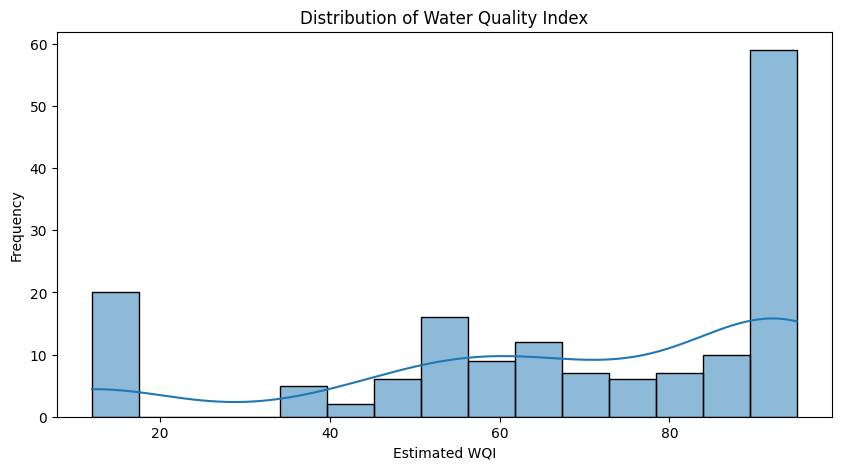

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['estimated_wqi'],
    bins=15,
    kde=True
)

plt.title('Distribution of Water Quality Index')
plt.xlabel('Estimated WQI')
plt.ylabel('Frequency')

plt.show()

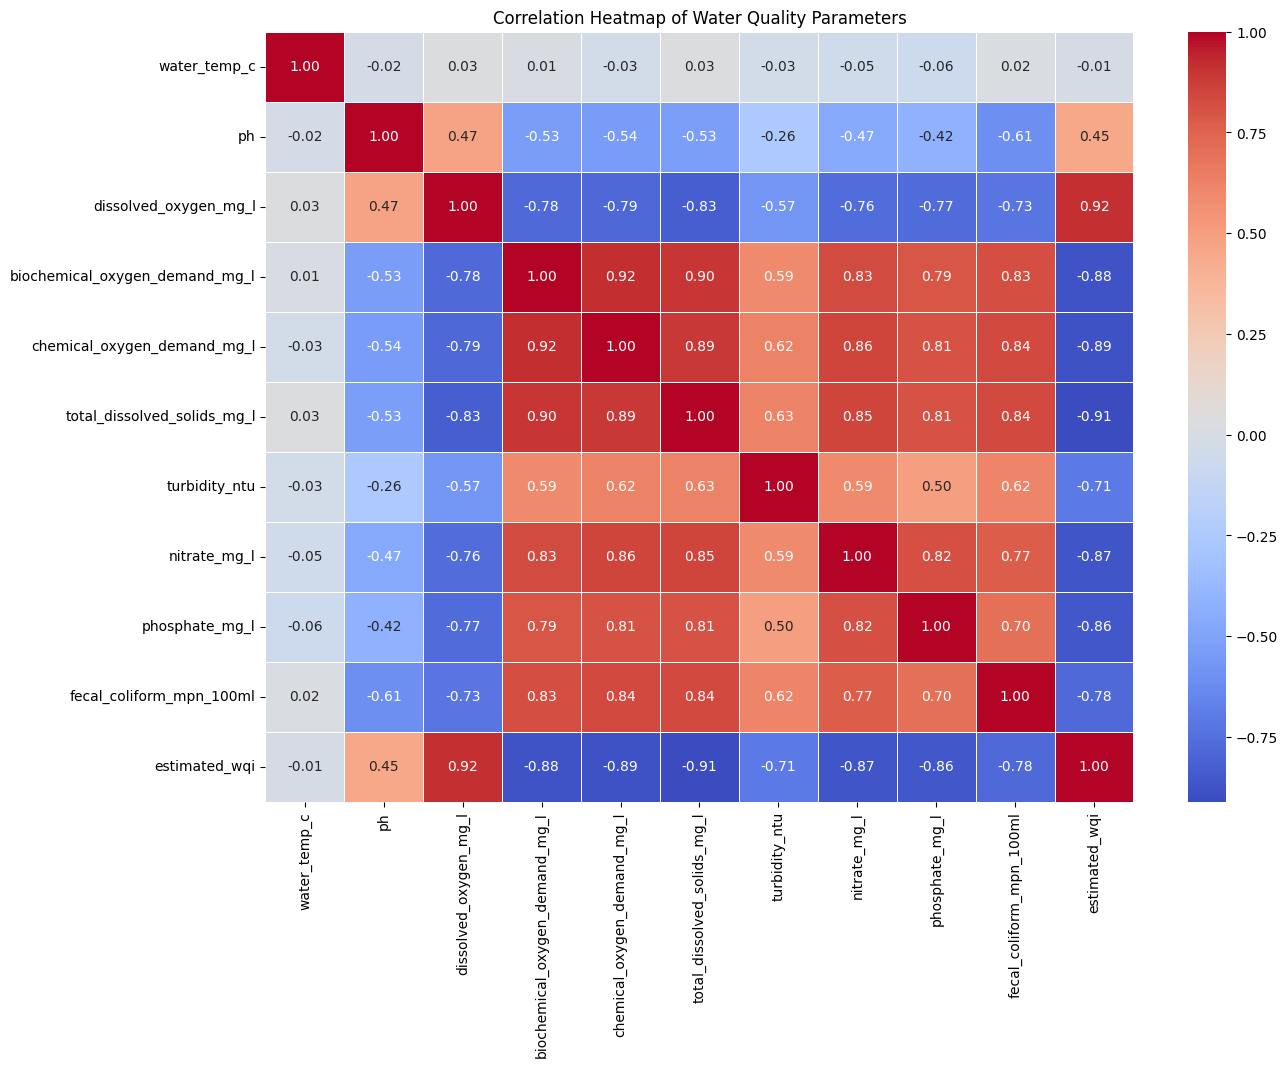

In [ ]:
plt.figure(figsize=(14, 10))

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Water Quality Parameters')

plt.show()

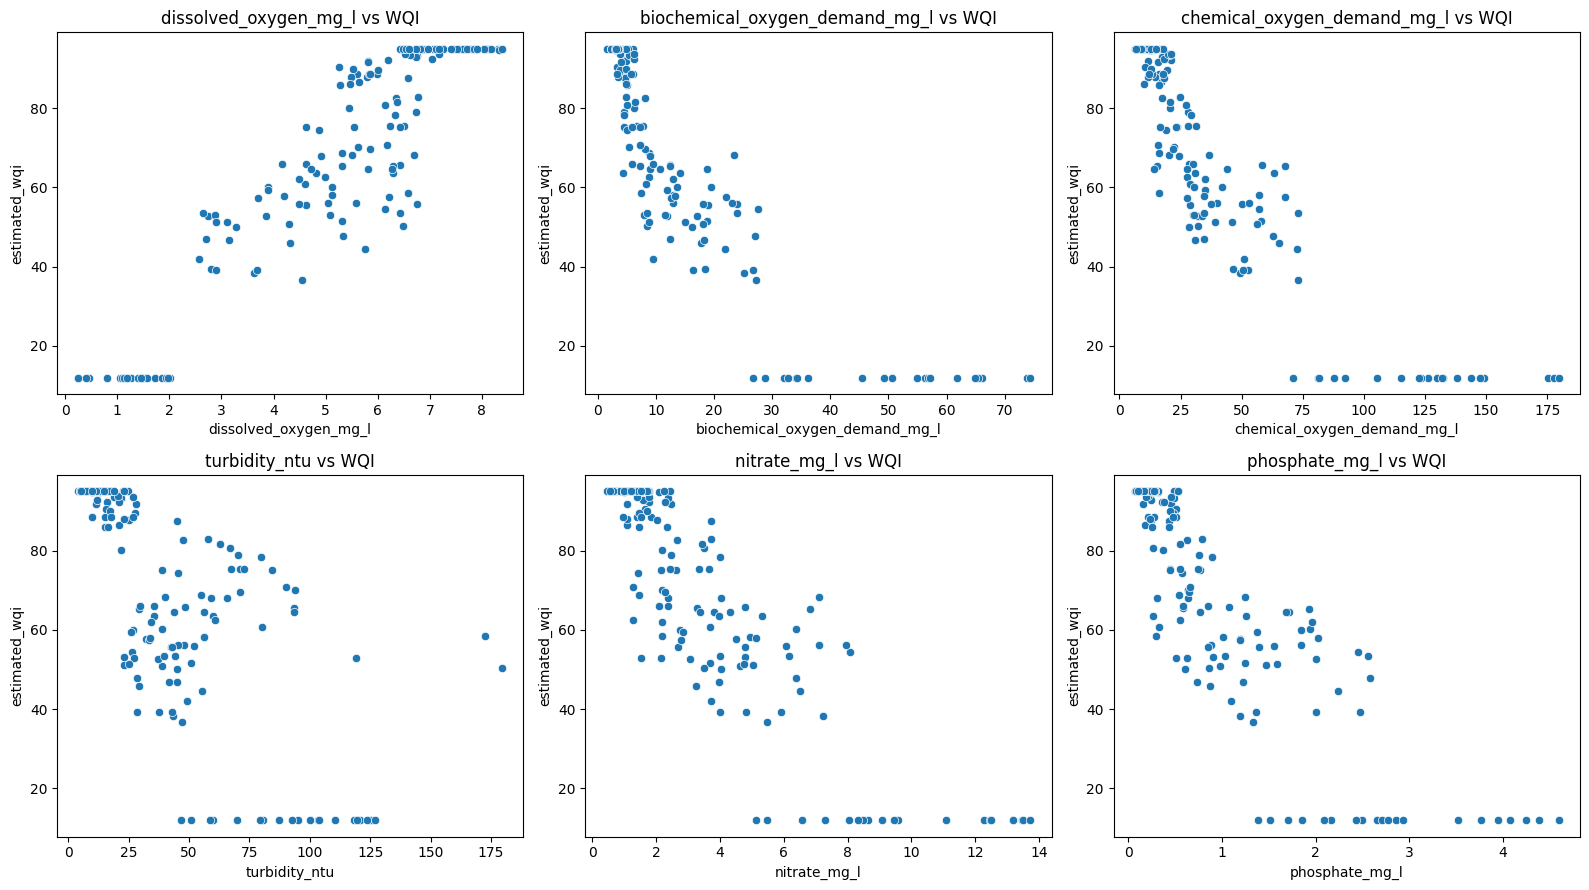

In [ ]:
parameters = [
    'dissolved_oxygen_mg_l',
    'biochemical_oxygen_demand_mg_l',
    'chemical_oxygen_demand_mg_l',
    'turbidity_ntu',
    'nitrate_mg_l',
    'phosphate_mg_l'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, parameter in zip(axes.flatten(), parameters):

    sns.scatterplot(
        data=df,
        x=parameter,
        y='estimated_wqi',
        ax=ax
    )

    ax.set_title(f'{parameter} vs WQI')

plt.tight_layout()
plt.show()

In [ ]:
print(df['estimated_wqi'].value_counts().sort_index())

estimated_wqi
12.0    20
36.7     1
38.4     1
39.2     2
39.3     1
        ..
93.5     1
93.6     1
93.8     1
94.8     2
95.0    45
Name: count, Length: 84, dtype: int64


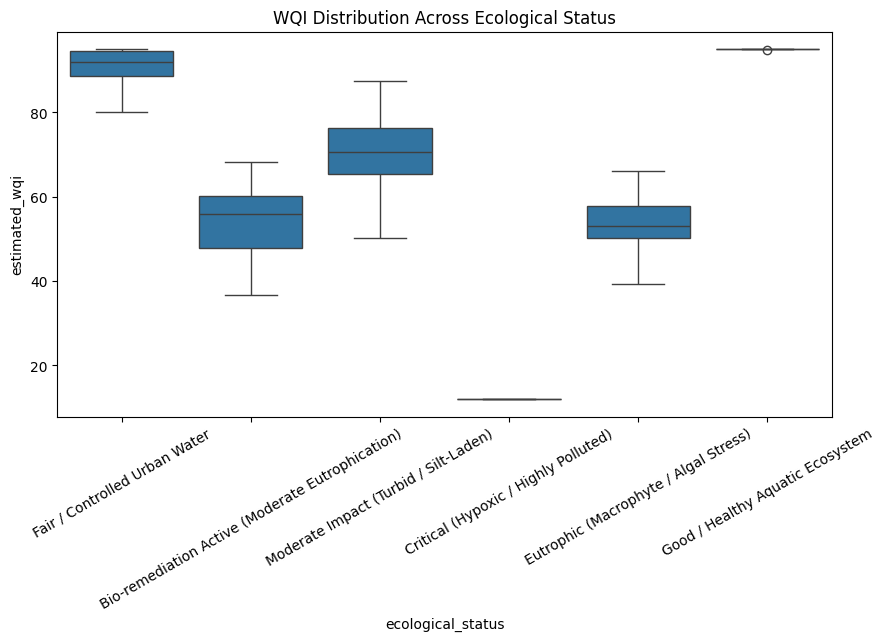

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='ecological_status',
    y='estimated_wqi'
)

plt.title('WQI Distribution Across Ecological Status')
plt.xticks(rotation=30)
plt.show()

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

print("Correlation with estimated WQI:\n")

print(
    correlation['estimated_wqi']
    .sort_values(ascending=False)
)

Correlation with estimated WQI:

estimated_wqi                     1.000000
dissolved_oxygen_mg_l             0.915807
ph                                0.450229
water_temp_c                     -0.010221
turbidity_ntu                    -0.707425
fecal_coliform_mpn_100ml         -0.781587
phosphate_mg_l                   -0.859152
nitrate_mg_l                     -0.870797
biochemical_oxygen_demand_mg_l   -0.875453
chemical_oxygen_demand_mg_l      -0.885339
total_dissolved_solids_mg_l      -0.910286
Name: estimated_wqi, dtype: float64


In [ ]:
print(df['estimated_wqi'].value_counts().sort_index())

estimated_wqi
12.0    20
36.7     1
38.4     1
39.2     2
39.3     1
        ..
93.5     1
93.6     1
93.8     1
94.8     2
95.0    45
Name: count, Length: 84, dtype: int64


In [ ]:
print(
    df.groupby('ecological_status')['estimated_wqi']
    .agg(['count', 'mean', 'min', 'max'])
)

                                                  count       mean   min   max
ecological_status                                                             
Bio-remediation Active (Moderate Eutrophication)     21  54.028571  36.7  68.3
Critical (Hypoxic / Highly Polluted)                 20  12.000000  12.0  12.0
Eutrophic (Macrophyte / Algal Stress)                21  53.223810  39.2  66.0
Fair / Controlled Urban Water                        30  91.116667  80.1  95.0
Good / Healthy Aquatic Ecosystem                     39  94.994872  94.8  95.0
Moderate Impact (Turbid / Silt-Laden)                28  70.860714  50.3  87.5


In [ ]:
print(
    df.groupby('water_body_name')['estimated_wqi']
    .agg(['count', 'mean', 'min', 'max'])
)

                                       count       mean   min   max
water_body_name                                                    
Adi Ganga (Tolly's Nullah)                 9  12.000000  12.0  12.0
Bally Canal                                9  95.000000  95.0  95.0
Bikramgarh Jheel                          10  55.470000  42.0  66.0
Central Park Jheel (Banabitan)            11  95.000000  95.0  95.0
Circular Canal (Bagbazar Canal)           11  12.000000  12.0  12.0
East Kolkata Wetlands (Captain Bheri)     11  55.227273  36.7  65.3
East Kolkata Wetlands (Nalban Bheri)      10  52.710000  38.4  68.3
Eco Park Lake (Prakriti Tirtha)            9  95.000000  95.0  95.0
Hooghly River (Babu Ghat)                  9  68.622222  50.3  82.9
Hooghly River (Dakshineswar Ghat)         10  72.250000  53.0  82.6
Hooghly River (Prinsep Ghat)               9  71.555556  58.5  87.5
Laldighi (Tank Square)                    10  94.980000  94.8  95.0
Puddapukur Water Reservoir                10  91

In [ ]:
features = [
    'water_body_type',
    'district',
    'location_zone',
    'season',
    'water_temp_c',
    'ph',
    'dissolved_oxygen_mg_l',
    'biochemical_oxygen_demand_mg_l',
    'chemical_oxygen_demand_mg_l',
    'total_dissolved_solids_mg_l',
    'turbidity_ntu',
    'nitrate_mg_l',
    'phosphate_mg_l',
    'fecal_coliform_mpn_100ml',
    'sensor_platform'
]

X = df[features]
y = df['estimated_wqi']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (159, 15)
y shape: (159,)


In [ ]:
categorical_features = [
    'water_body_type',
    'district',
    'location_zone',
    'season',
    'sensor_platform'
]

numerical_features = [
    col for col in features
    if col not in categorical_features
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['water_body_type', 'district', 'location_zone', 'season', 'sensor_platform']

Numerical features:
['water_temp_c', 'ph', 'dissolved_oxygen_mg_l', 'biochemical_oxygen_demand_mg_l', 'chemical_oxygen_demand_mg_l', 'total_dissolved_solids_mg_l', 'turbidity_ntu', 'nitrate_mg_l', 'phosphate_mg_l', 'fecal_coliform_mpn_100ml']


In [ ]:
correlation = df.select_dtypes(
    include=np.number
).corr()

wqi_correlation = correlation['estimated_wqi'].sort_values(
    ascending=False
)

print("Correlation with WQI:")
print(wqi_correlation)

Correlation with WQI:
estimated_wqi                     1.000000
dissolved_oxygen_mg_l             0.915807
ph                                0.450229
water_temp_c                     -0.010221
turbidity_ntu                    -0.707425
fecal_coliform_mpn_100ml         -0.781587
phosphate_mg_l                   -0.859152
nitrate_mg_l                     -0.870797
biochemical_oxygen_demand_mg_l   -0.875453
chemical_oxygen_demand_mg_l      -0.885339
total_dissolved_solids_mg_l      -0.910286
Name: estimated_wqi, dtype: float64


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kolkata_water_bodies_monitoring_dataset.csv to kolkata_water_bodies_monitoring_dataset (1).csv


In [ ]:
df = pd.read_csv('kolkata_water_bodies_monitoring_dataset.csv')

print("Dataset loaded:", df.shape)

Dataset loaded: (159, 20)


In [ ]:
correlation = df.select_dtypes(
    include=np.number
).corr()

wqi_correlation = correlation['estimated_wqi'].sort_values(
    ascending=False
)

print("Correlation with WQI:")
print(wqi_correlation)

Correlation with WQI:
estimated_wqi                     1.000000
dissolved_oxygen_mg_l             0.915807
ph                                0.450229
water_temp_c                     -0.010221
turbidity_ntu                    -0.707425
fecal_coliform_mpn_100ml         -0.781587
phosphate_mg_l                   -0.859152
nitrate_mg_l                     -0.870797
biochemical_oxygen_demand_mg_l   -0.875453
chemical_oxygen_demand_mg_l      -0.885339
total_dissolved_solids_mg_l      -0.910286
Name: estimated_wqi, dtype: float64


## Feature Analysis and Data Leakage Investigation

In this section, we investigate the relationship between
ecological status and the estimated Water Quality Index.

The objective is to identify potential target leakage
before training the regression model.

In [ ]:
print("Ecological Status Distribution:")

print(df['ecological_status'].value_counts())

Ecological Status Distribution:
ecological_status
Good / Healthy Aquatic Ecosystem                    39
Fair / Controlled Urban Water                       30
Moderate Impact (Turbid / Silt-Laden)               28
Bio-remediation Active (Moderate Eutrophication)    21
Eutrophic (Macrophyte / Algal Stress)               21
Critical (Hypoxic / Highly Polluted)                20
Name: count, dtype: int64


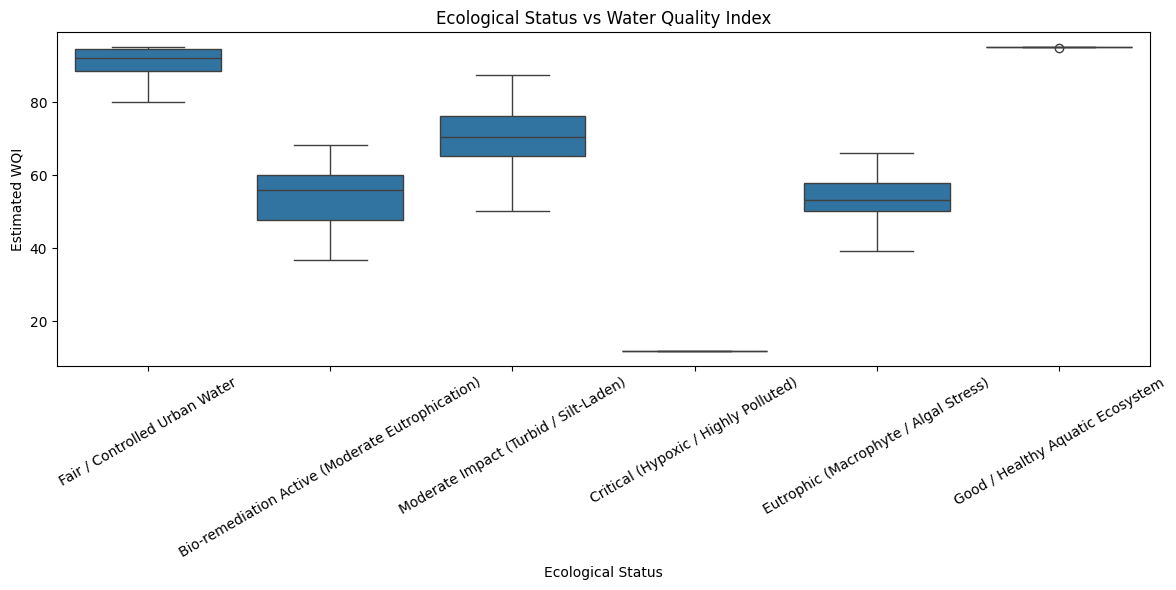

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='ecological_status',
    y='estimated_wqi'
)

plt.title('Ecological Status vs Water Quality Index')
plt.xlabel('Ecological Status')
plt.ylabel('Estimated WQI')

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

In [ ]:
water_body_analysis = df.groupby(
    'water_body_name'
)['estimated_wqi'].agg(
    ['count', 'mean', 'min', 'max', 'std']
)

print(water_body_analysis)

                                       count       mean   min   max        std
water_body_name                                                               
Adi Ganga (Tolly's Nullah)                 9  12.000000  12.0  12.0   0.000000
Bally Canal                                9  95.000000  95.0  95.0   0.000000
Bikramgarh Jheel                          10  55.470000  42.0  66.0   7.426836
Central Park Jheel (Banabitan)            11  95.000000  95.0  95.0   0.000000
Circular Canal (Bagbazar Canal)           11  12.000000  12.0  12.0   0.000000
East Kolkata Wetlands (Captain Bheri)     11  55.227273  36.7  65.3   7.625102
East Kolkata Wetlands (Nalban Bheri)      10  52.710000  38.4  68.3  11.116999
Eco Park Lake (Prakriti Tirtha)            9  95.000000  95.0  95.0   0.000000
Hooghly River (Babu Ghat)                  9  68.622222  50.3  82.9   9.792826
Hooghly River (Dakshineswar Ghat)         10  72.250000  53.0  82.6   8.732983
Hooghly River (Prinsep Ghat)               9  71.555

In [ ]:
variation = df.groupby('water_body_name')['estimated_wqi'].std()

print("WQI Standard Deviation by Water Body:")
print(variation)

print("\nWater bodies with constant WQI:")

print(variation[variation == 0])

WQI Standard Deviation by Water Body:
water_body_name
Adi Ganga (Tolly's Nullah)                0.000000
Bally Canal                               0.000000
Bikramgarh Jheel                          7.426836
Central Park Jheel (Banabitan)            0.000000
Circular Canal (Bagbazar Canal)           0.000000
East Kolkata Wetlands (Captain Bheri)     7.625102
East Kolkata Wetlands (Nalban Bheri)     11.116999
Eco Park Lake (Prakriti Tirtha)           0.000000
Hooghly River (Babu Ghat)                 9.792826
Hooghly River (Dakshineswar Ghat)         8.732983
Hooghly River (Prinsep Ghat)              9.453189
Laldighi (Tank Square)                    0.063246
Puddapukur Water Reservoir                3.258851
Rabindra Sarobar (Dhakuria Lake)          2.891059
Santragachi Jheel                         7.275551
Subhash Sarobar (Beliaghata Lake)         4.980451
Name: estimated_wqi, dtype: float64

Water bodies with constant WQI:
water_body_name
Adi Ganga (Tolly's Nullah)         0.0
Bally 

In [ ]:
status_analysis = df.groupby(
    'ecological_status'
)['estimated_wqi'].agg(
    ['count', 'mean', 'min', 'max', 'std']
)

print(status_analysis)

                                                  count       mean   min  \
ecological_status                                                          
Bio-remediation Active (Moderate Eutrophication)     21  54.028571  36.7   
Critical (Hypoxic / Highly Polluted)                 20  12.000000  12.0   
Eutrophic (Macrophyte / Algal Stress)                21  53.223810  39.2   
Fair / Controlled Urban Water                        30  91.116667  80.1   
Good / Healthy Aquatic Ecosystem                     39  94.994872  94.8   
Moderate Impact (Turbid / Silt-Laden)                28  70.860714  50.3   

                                                   max       std  
ecological_status                                                 
Bio-remediation Active (Moderate Eutrophication)  68.3  9.292209  
Critical (Hypoxic / Highly Polluted)              12.0  0.000000  
Eutrophic (Macrophyte / Algal Stress)             66.0  7.490254  
Fair / Controlled Urban Water                     95.0  

## Feature Selection and Data Preparation

The dataset is divided into input features (X) and
the target variable (y).

Categorical features will be encoded using One-Hot Encoding.

Numerical features will be retained in their original scale.

The water body name will be retained separately
for group-based model evaluation.

In [ ]:
categorical_features = [
    'water_body_type',
    'district',
    'location_zone',
    'season',
    'sensor_platform'
]

numerical_features = [
    'water_temp_c',
    'ph',
    'dissolved_oxygen_mg_l',
    'biochemical_oxygen_demand_mg_l',
    'chemical_oxygen_demand_mg_l',
    'total_dissolved_solids_mg_l',
    'turbidity_ntu',
    'nitrate_mg_l',
    'phosphate_mg_l',
    'fecal_coliform_mpn_100ml'
]

features = categorical_features + numerical_features

target = 'estimated_wqi'

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Total input features:", len(features))

Categorical features: 5
Numerical features: 10
Total input features: 15


In [ ]:
X = df[features]

y = df[target]

groups = df['water_body_name']

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Groups:", groups.nunique())

X shape: (159, 15)
y shape: (159,)
Groups: 16


In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numerical',
            'passthrough',
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining water bodies:")
print(groups.iloc[train_idx].unique())

print("\nTesting water bodies:")
print(groups.iloc[test_idx].unique())

Training records: 119
Testing records: 40

Training water bodies:
['Rabindra Sarobar (Dhakuria Lake)' 'Subhash Sarobar (Beliaghata Lake)'
 'East Kolkata Wetlands (Nalban Bheri)' 'Hooghly River (Babu Ghat)'
 'Hooghly River (Dakshineswar Ghat)' 'Hooghly River (Prinsep Ghat)'
 'Circular Canal (Bagbazar Canal)' 'Central Park Jheel (Banabitan)'
 'Eco Park Lake (Prakriti Tirtha)' 'Puddapukur Water Reservoir'
 'Laldighi (Tank Square)' 'Bikramgarh Jheel']

Testing water bodies:
['East Kolkata Wetlands (Captain Bheri)' "Adi Ganga (Tolly's Nullah)"
 'Santragachi Jheel' 'Bally Canal']


In [ ]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    random_state=42,
    objective='reg:squarederror'
)

model_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', xgb_model)
    ]
)

model_pipeline.fit(X_train, y_train)

print("XGBoost model training completed!")

XGBoost model training completed!


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

Model Evaluation Results
-------------------------
MAE: 4.137
RMSE: 5.591
R2 Score: 0.961


In [ ]:
results = pd.DataFrame({
    'Water Body': df.iloc[test_idx]['water_body_name'].values,
    'Actual WQI': y_test.values,
    'Predicted WQI': y_pred
})

results['Error'] = results['Actual WQI'] - results['Predicted WQI']

print(results.round(2).to_string(index=False))

                           Water Body  Actual WQI  Predicted WQI  Error
East Kolkata Wetlands (Captain Bheri)        57.6      55.549999   2.05
East Kolkata Wetlands (Captain Bheri)        65.3      56.330002   8.97
East Kolkata Wetlands (Captain Bheri)        51.6      55.869999  -4.27
East Kolkata Wetlands (Captain Bheri)        50.9      54.840000  -3.94
East Kolkata Wetlands (Captain Bheri)        36.7      43.270000  -6.57
East Kolkata Wetlands (Captain Bheri)        58.2      55.770000   2.43
East Kolkata Wetlands (Captain Bheri)        64.6      63.349998   1.25
East Kolkata Wetlands (Captain Bheri)        55.9      59.930000  -4.03
East Kolkata Wetlands (Captain Bheri)        56.1      57.259998  -1.16
East Kolkata Wetlands (Captain Bheri)        54.5      56.480000  -1.98
East Kolkata Wetlands (Captain Bheri)        56.1      56.090000   0.01
           Adi Ganga (Tolly's Nullah)        12.0      19.520000  -7.52
           Adi Ganga (Tolly's Nullah)        12.0      18.889999

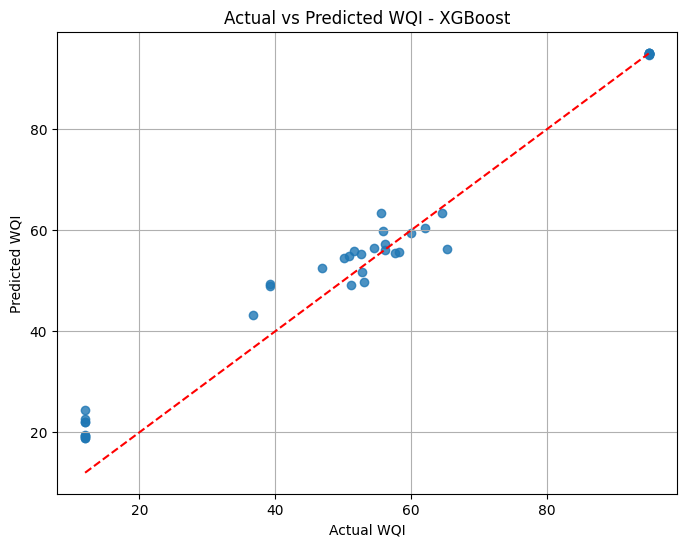

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.8)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual WQI")
plt.ylabel("Predicted WQI")
plt.title("Actual vs Predicted WQI - XGBoost")
plt.grid(True)

plt.show()

In [ ]:
results['Absolute Error'] = abs(results['Error'])

body_performance = results.groupby('Water Body').agg(
    Actual_Mean=('Actual WQI', 'mean'),
    Predicted_Mean=('Predicted WQI', 'mean'),
    MAE=('Absolute Error', 'mean'),
    Records=('Actual WQI', 'count')
).round(3)

print(body_performance)

                                       Actual_Mean  Predicted_Mean    MAE  \
Water Body                                                                  
Adi Ganga (Tolly's Nullah)                  12.000       20.742001  8.742   
Bally Canal                                 95.000       94.949997  0.104   
East Kolkata Wetlands (Captain Bheri)       55.227       55.884998  3.333   
Santragachi Jheel                           51.182       54.077999  4.475   

                                       Records  
Water Body                                      
Adi Ganga (Tolly's Nullah)                   9  
Bally Canal                                  9  
East Kolkata Wetlands (Captain Bheri)       11  
Santragachi Jheel                           11  


In [ ]:
print("Maximum absolute error:",
      round(results['Absolute Error'].max(), 3))

print("Minimum absolute error:",
      round(results['Absolute Error'].min(), 3))

print("Median absolute error:",
      round(results['Absolute Error'].median(), 3))

print("Predictions within 5 WQI points:",
      (results['Absolute Error'] <= 5).sum(),
      "out of", len(results))

print("Predictions within 10 WQI points:",
      (results['Absolute Error'] <= 10).sum(),
      "out of", len(results))

Maximum absolute error: 12.43
Minimum absolute error: 0.003
Median absolute error: 2.986
Predictions within 5 WQI points: 25 out of 40
Predictions within 10 WQI points: 35 out of 40


In [ ]:
print("Unique WQI values:", df['estimated_wqi'].nunique())

print("\nMost frequent WQI values:")
print(df['estimated_wqi'].value_counts().head(15))

print("\nMinimum WQI:", df['estimated_wqi'].min())
print("Maximum WQI:", df['estimated_wqi'].max())

print("\nWQI values equal to 12:",
      (df['estimated_wqi'] == 12).sum())

print("WQI values equal to 95:",
      (df['estimated_wqi'] == 95).sum())

Unique WQI values: 84

Most frequent WQI values:
estimated_wqi
95.0    45
12.0    20
88.6     4
64.6     3
53.5     2
56.1     2
75.2     2
66.0     2
39.2     2
63.6     2
94.8     2
86.6     1
89.6     1
85.9     1
92.2     1
Name: count, dtype: int64

Minimum WQI: 12.0
Maximum WQI: 95.0

WQI values equal to 12: 20
WQI values equal to 95: 45


In [ ]:
print(
    df[
        numerical_features + ['estimated_wqi']
    ].corr()['estimated_wqi'].sort_values(ascending=False)
)

estimated_wqi                     1.000000
dissolved_oxygen_mg_l             0.915807
ph                                0.450229
water_temp_c                     -0.010221
turbidity_ntu                    -0.707425
fecal_coliform_mpn_100ml         -0.781587
phosphate_mg_l                   -0.859152
nitrate_mg_l                     -0.870797
biochemical_oxygen_demand_mg_l   -0.875453
chemical_oxygen_demand_mg_l      -0.885339
total_dissolved_solids_mg_l      -0.910286
Name: estimated_wqi, dtype: float64


In [ ]:
importance = model_pipeline.named_steps['model'].feature_importances_

feature_names = (
    model_pipeline.named_steps['preprocessor']
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df.to_string(index=False))

                                                                 Feature  Importance
                               numerical__biochemical_oxygen_demand_mg_l    0.306570
                                  numerical__chemical_oxygen_demand_mg_l    0.213132
                          categorical__water_body_type_River / Estuarine    0.093814
                                               numerical__phosphate_mg_l    0.088674
                                        numerical__dissolved_oxygen_mg_l    0.065758
                                categorical__location_zone_North Kolkata    0.055770
                                     numerical__fecal_coliform_mpn_100ml    0.035824
                       categorical__water_body_type_Urban Drainage Canal    0.033756
                                                numerical__turbidity_ntu    0.029845
                                  numerical__total_dissolved_solids_mg_l    0.026779
                categorical__district_North 24 Parganas / Kolkata

In [ ]:
residuals = y_test - y_pred

error_df = pd.DataFrame({
    'Actual WQI': y_test.values,
    'Predicted WQI': y_pred,
    'Residual': residuals,
    'Absolute Error': np.abs(residuals)
})

print(error_df.describe())

       Actual WQI  Predicted WQI   Residual  Absolute Error
count   40.000000      40.000000  40.000000       40.000000
mean    53.337500      56.270546  -2.933044        4.137450
std     28.734922      25.523962   4.820675        3.808517
min     12.000000      18.790901 -12.429585        0.002777
25%     38.575000      47.528437  -6.960631        0.522357
50%     53.800000      55.658064  -1.567804        2.986057
75%     64.775000      63.386114   0.215687        7.177913
max     95.000000      95.151970   8.966550       12.429585


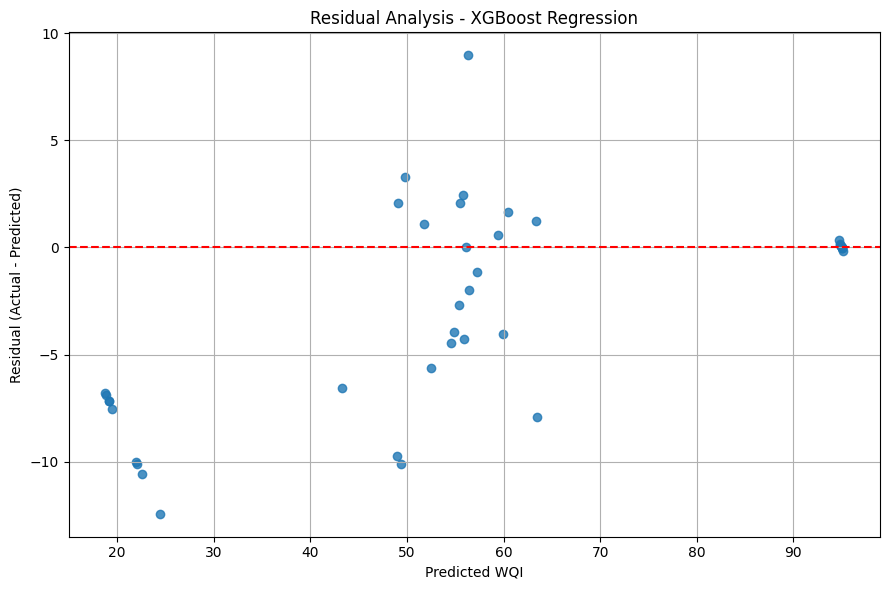

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.8
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel('Predicted WQI')
plt.ylabel('Residual (Actual - Predicted)')
plt.title('Residual Analysis - XGBoost Regression')
plt.grid(True)
plt.tight_layout()

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
models = {
    'XGBoost': XGBRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        random_state=42,
        objective='reg:squarederror'
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=300,
        max_depth=5,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=2,
        random_state=42
    )
}

results = []

for name, algorithm in models.items():

    pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('model', algorithm)
        ]
    )

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.to_string(index=False))

            Model      MAE     RMSE  R2 Score
          XGBoost 4.137450 5.591125  0.961169
    Random Forest 4.446692 5.938143  0.956200
Gradient Boosting 2.792940 3.802066  0.982044


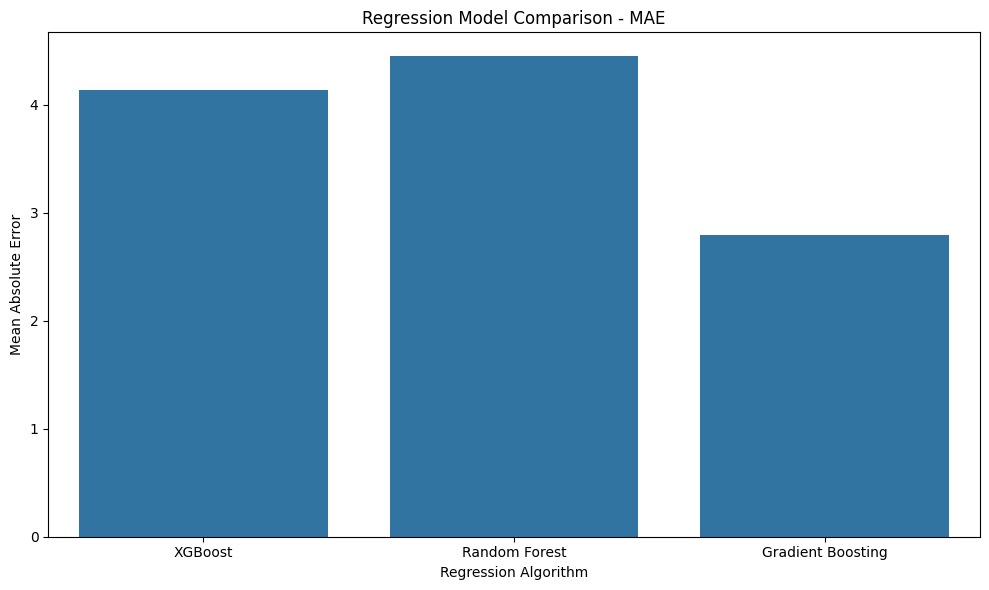

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_df,
    x='Model',
    y='MAE'
)

plt.title('Regression Model Comparison - MAE')
plt.xlabel('Regression Algorithm')
plt.ylabel('Mean Absolute Error')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import GroupKFold, cross_validate

group_kfold = GroupKFold(n_splits=5)

cv_models = {
    'XGBoost': models['XGBoost'],
    'Random Forest': models['Random Forest'],
    'Gradient Boosting': models['Gradient Boosting']
}

cv_results = []

for name, algorithm in cv_models.items():

    pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('model', algorithm)
        ]
    )

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=group_kfold,
        groups=groups,
        scoring={
            'MAE': 'neg_mean_absolute_error',
            'RMSE': 'neg_root_mean_squared_error',
            'R2': 'r2'
        }
    )

    cv_results.append({
        'Model': name,
        'Mean MAE': -scores['test_MAE'].mean(),
        'Mean RMSE': -scores['test_RMSE'].mean(),
        'Mean R2': scores['test_R2'].mean(),
        'Std MAE': scores['test_MAE'].std(),
        'Std R2': scores['test_R2'].std()
    })

cv_df = pd.DataFrame(cv_results)

print(cv_df.to_string(index=False))

            Model  Mean MAE  Mean RMSE  Mean R2  Std MAE   Std R2
          XGBoost  3.104141   4.330379 0.947845 1.043681 0.022382
    Random Forest  3.640595   5.152251 0.930241 1.711311 0.032187
Gradient Boosting  2.737720   3.744023 0.958422 0.947036 0.029753


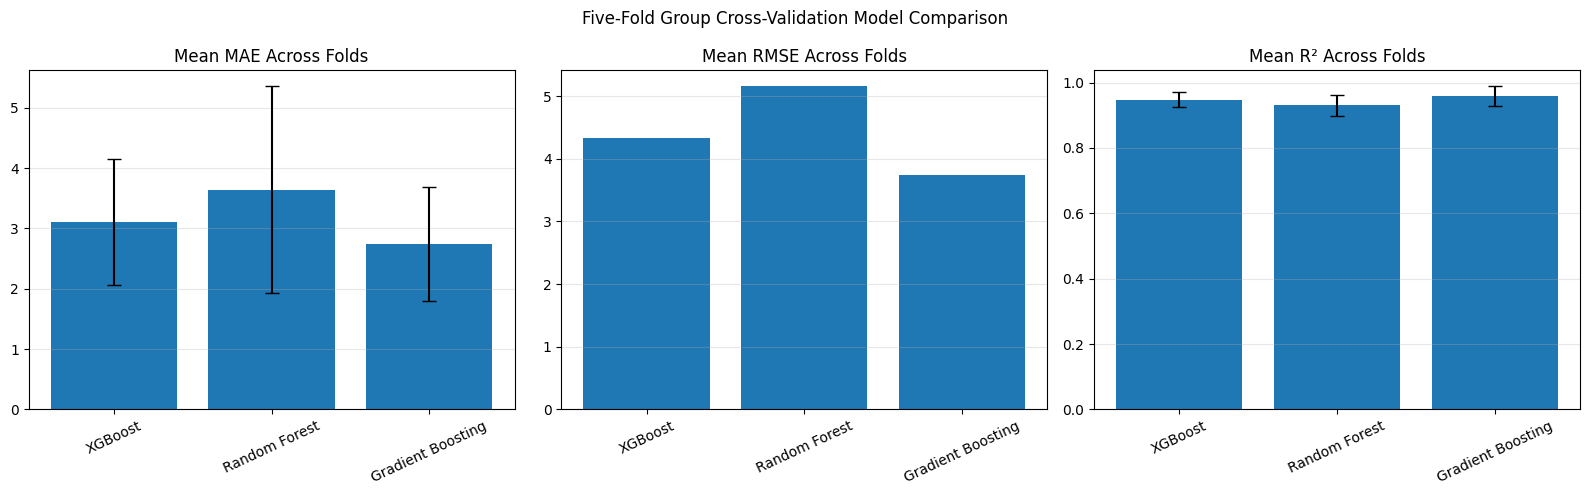

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = [
    ('Mean MAE', 'Std MAE', 'Mean MAE Across Folds'),
    ('Mean RMSE', None, 'Mean RMSE Across Folds'),
    ('Mean R2', 'Std R2', 'Mean R² Across Folds')
]

for ax, (metric, std_metric, title) in zip(axes, metrics):

    errors = cv_df[std_metric] if std_metric else None

    ax.bar(
        cv_df['Model'],
        cv_df[metric],
        yerr=errors,
        capsize=5
    )

    ax.set_title(title)
    ax.tick_params(axis='x', rotation=25)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Five-Fold Group Cross-Validation Model Comparison')
plt.tight_layout()
plt.show()

In [ ]:
final_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.03,
            max_depth=2,
            random_state=42
        ))
    ]
)

final_model.fit(X_train, y_train)

final_predictions = final_model.predict(X_test)

final_mae = mean_absolute_error(
    y_test, final_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(y_test, final_predictions)
)

final_r2 = r2_score(
    y_test, final_predictions
)

print("Final Gradient Boosting Model Evaluation")
print("----------------------------------------")
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R2 Score:", final_r2)

Final Gradient Boosting Model Evaluation
----------------------------------------
MAE: 2.792939585208856
RMSE: 3.8020659842847078
R2 Score: 0.9820437914318584


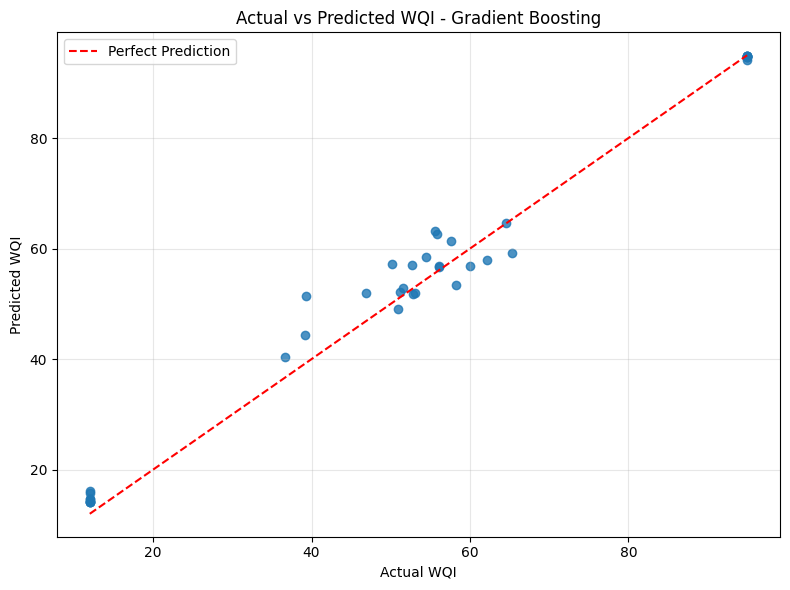

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.8
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual WQI')
plt.ylabel('Predicted WQI')
plt.title('Actual vs Predicted WQI - Gradient Boosting')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
gb_importance = final_model.named_steps['model'].feature_importances_

gb_feature_names = (
    final_model.named_steps['preprocessor']
    .get_feature_names_out()
)

gb_importance_df = pd.DataFrame({
    'Feature': gb_feature_names,
    'Importance': gb_importance
})

gb_importance_df = gb_importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(gb_importance_df.to_string(index=False))

                                                                 Feature  Importance
                                  numerical__chemical_oxygen_demand_mg_l    0.352742
                               numerical__biochemical_oxygen_demand_mg_l    0.260305
                                        numerical__dissolved_oxygen_mg_l    0.237052
                                     numerical__fecal_coliform_mpn_100ml    0.068208
                                  numerical__total_dissolved_solids_mg_l    0.028912
                                                numerical__turbidity_ntu    0.027495
                       categorical__water_body_type_Urban Drainage Canal    0.016726
                          categorical__water_body_type_River / Estuarine    0.006482
                                                           numerical__ph    0.001515
                                               numerical__phosphate_mg_l    0.000379
                                                 numerical__water

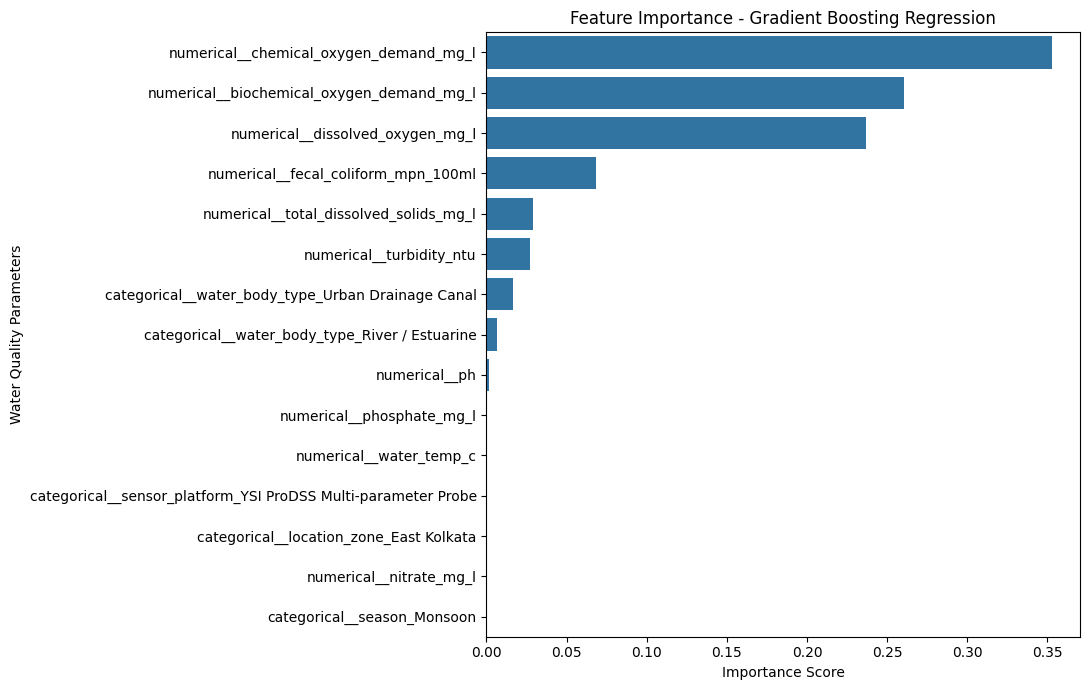

In [ ]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=gb_importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Gradient Boosting Regression')
plt.xlabel('Importance Score')
plt.ylabel('Water Quality Parameters')

plt.tight_layout()
plt.show()

In [ ]:
final_residuals = y_test - final_predictions

final_error_df = pd.DataFrame({
    'Actual WQI': y_test.values,
    'Predicted WQI': final_predictions,
    'Residual': final_residuals,
    'Absolute Error': np.abs(final_residuals)
})

print(final_error_df.describe())

       Actual WQI  Predicted WQI   Residual  Absolute Error
count   40.000000      40.000000  40.000000       40.000000
mean    53.337500      54.905080  -1.567580        2.792940
std     28.734922      27.543332   3.507998        2.612631
min     12.000000      14.124603 -12.103507        0.062480
25%     38.575000      43.314876  -3.771283        0.730887
50%     53.800000      56.749725  -1.172311        2.161394
75%     64.775000      63.514359   0.245622        4.091707
max     95.000000      94.937520   6.036022       12.103507


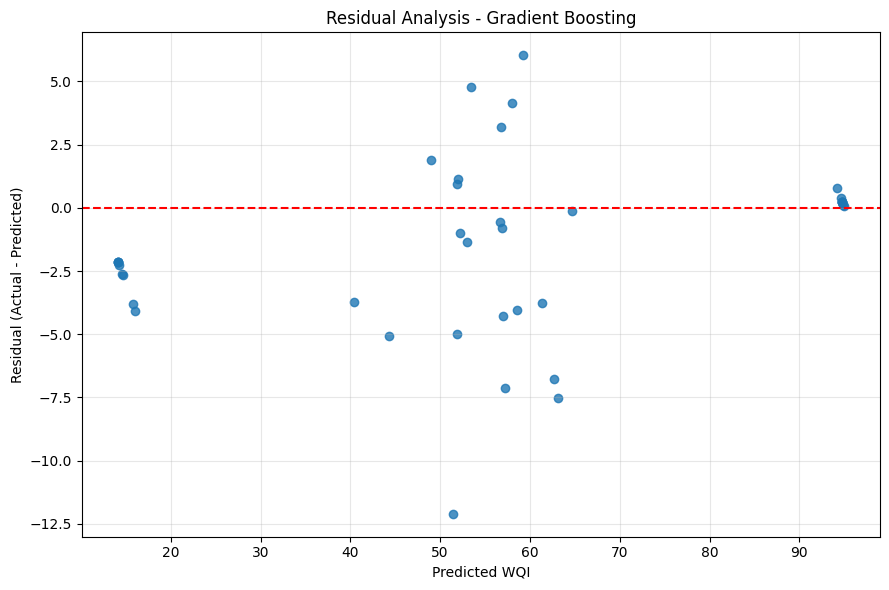

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    final_predictions,
    final_residuals,
    alpha=0.8
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel('Predicted WQI')
plt.ylabel('Residual (Actual - Predicted)')
plt.title('Residual Analysis - Gradient Boosting')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import joblib
import os

os.makedirs('model_artifacts', exist_ok=True)

joblib.dump(
    final_model,
    'model_artifacts/gradient_boosting_wqi.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
loaded_model = joblib.load(
    'model_artifacts/gradient_boosting_wqi.pkl'
)

test_predictions = loaded_model.predict(X_test)

print("Loaded model MAE:",
      mean_absolute_error(y_test, test_predictions))

print("Loaded model R2:",
      r2_score(y_test, test_predictions))

Loaded model MAE: 2.792939585208856
Loaded model R2: 0.9820437914318584
